# Milestone 4 -- Formulating the MCQ Task & Fine-Tuning

**Goals**
1. Data formatting for MCQ: concatenating the question with options
2. LoRA fine-tuning, and its advantages over full fine-tuning
3. Setting up a real training loop
4. Managing GPU memory and batch sizes
5. Training-efficiency strategies via `TrainingArguments`

CPU-only machine, no GPU. This notebook runs a **real, small-scale**
LoRA fine-tune (subsampled data, short sequences, few steps) to prove the
whole pipeline is correct end-to-end. Section 6 spells out exactly what to
change to scale this to the full training set on a GPU (Kaggle/Colab) --
the code itself doesn't change, only the constants.


In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForMultipleChoice, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model

from mcq_formatting import preprocess_for_multiple_choice, DataCollatorForMultipleChoice, OPTION_COLS
from metrics import mean_average_precision_at_k

torch.manual_seed(42)
GPU_AVAILABLE = torch.cuda.is_available()
print('GPU available:', GPU_AVAILABLE)

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\torch\cuda\__init__.py:64: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU available: False


## 1. Data formatting: concatenating question + options

`AutoModelForMultipleChoice` expects, per example, `num_choices` separately
tokenized (question, option) *sequence pairs* stacked into one
`[num_choices, seq_len]` block (batched further to
`[batch, num_choices, seq_len]`) -- not one long concatenated string of
all 5 options. The tokenizer inserts an explicit `[SEP]` between question
and option, and the model scores all 5 choices for a question jointly
(softmax over the 5 logits), rather than treating each option as an
independent binary classification the way milestone 2's zero-shot setup
did.

`src/mcq_formatting.py` implements this with `datasets.Dataset.map` (the
HF-idiomatic way -- same `.map()` interface milestone 2 introduced) plus a
`DataCollatorForMultipleChoice` that dynamically pads each batch to its
own longest sequence rather than a fixed length (a real efficiency win:
no wasted compute on pad tokens for short examples in a batch of
otherwise-short examples).

In [2]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')

demo_row = pd.read_csv('../data/train.csv').iloc[0]
demo_ds = Dataset.from_pandas(pd.DataFrame([demo_row]))
demo_tok = demo_ds.map(lambda ex: preprocess_for_multiple_choice(ex, tokenizer, max_length=48), batched=True, remove_columns=demo_ds.column_names)

print('one example -> input_ids shape:', np.array(demo_tok[0]['input_ids']).shape, '(num_choices, seq_len)')
print('label (index of correct option):', demo_tok[0]['label'], '->', OPTION_COLS[demo_tok[0]['label']])
print()
print('decoded choice 0 (question + option A):')
print(tokenizer.decode(demo_tok[0]['input_ids'][0]))

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

Map: 100%|██████████| 1/1 [00:00<00:00, 22.84 examples/s]

one example -> input_ids shape: (5, 48) (num_choices, seq_len)
label (index of correct option): 1 -> B

decoded choice 0 (question + option A):
[CLS] pick the best possible answer : what is martin heidegger ' s view on the relationship between time and human [SEP] martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or [SEP]


## 2. LoRA vs. full fine-tuning

**Full fine-tuning** updates every weight in the model. For an optimizer
like Adam that keeps two extra running-average buffers per trainable
parameter (momentum + variance), the *training-time* memory cost is
roughly `weights + gradients + 2x optimizer state` = **~4x the parameter
count**, all in addition to activations. Every fine-tuned checkpoint is
also a full copy of the model.

**LoRA** (Low-Rank Adaptation) freezes the pretrained weights entirely and
injects a pair of small trainable matrices `B (d x r)` and `A (r x d)`
next to chosen frozen linear layers (here: each attention block's query
and value projections, `q_lin`/`v_lin`), so the effective update is
`W + BA` with rank `r << d`. Only `A`/`B` (and, here, the newly-added
classification head, which has no pretrained weights to freeze) are
trainable.

Advantages over full fine-tuning:
- **Far fewer trainable parameters** -> proportionally less optimizer-state
  memory and less compute spent on gradients for the frozen 99%+ of the
  network.
- **Tiny checkpoints** -- a LoRA adapter is megabytes, not hundreds of MB,
  so swapping between task-specific adapters on the same frozen base model
  is cheap.
- **Lower catastrophic-forgetting risk** -- the pretrained weights never
  move, only a small additive delta is learned.

In [3]:
base_model = AutoModelForMultipleChoice.from_pretrained('distilbert-base-uncased')
full_ft_params = sum(p.numel() for p in base_model.parameters())

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=['q_lin', 'v_lin'],
    modules_to_save=['pre_classifier', 'classifier'],  # new head has no pretrained weights -- must train it fully
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
bytes_per_param_fp32 = 4
full_ft_optimizer_bytes = full_ft_params * bytes_per_param_fp32 * 4   # weights + grad + 2 Adam moments
lora_optimizer_bytes = trainable * bytes_per_param_fp32 * 4

print(f'\nfull fine-tune: ~{full_ft_optimizer_bytes / 1e6:.1f} MB of weights+grads+optimizer-state ({full_ft_params:,} trainable params)')
print(f'LoRA:           ~{lora_optimizer_bytes / 1e6:.1f} MB of weights+grads+optimizer-state ({trainable:,} trainable params)')
print(f'reduction: {full_ft_optimizer_bytes / lora_optimizer_bytes:.1f}x less trainable-parameter memory')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2030.23it/s]


[transformers] DistilBertForMultipleChoice LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 738,817 || all params: 67,693,058 || trainable%: 1.0914

full fine-tune: ~1071.3 MB of weights+grads+optimizer-state (66,954,241 trainable params)
LoRA:           ~11.8 MB of weights+grads+optimizer-state (738,817 trainable params)
reduction: 90.6x less trainable-parameter memory


## 3. Managing GPU memory & batch size

None of this changes what fits on a GPU by itself (activation memory
still scales with `batch_size x num_choices x seq_len`), but a few
concrete levers matter here:

- **Gradient accumulation** (`gradient_accumulation_steps` below):
  simulate a larger effective batch size (`per_device_train_batch_size x
  gradient_accumulation_steps`) without holding a bigger batch's
  activations in memory at once -- accumulate gradients over several
  small forward/backward passes before stepping the optimizer.
- **Mixed precision** (`fp16`/`bf16`, GPU-only): storing activations and
  weights in 16-bit roughly halves memory and speeds up matmuls on tensor
  cores. Not available on this CPU-only machine (`torch.cuda.is_available()
  == False` here), so `fp16` is left off below and would be flipped on for
  a GPU run.
- **Gradient checkpointing**: recompute activations during the backward
  pass instead of storing all of them from the forward pass -- trades
  extra compute for a large activation-memory reduction, useful when
  `seq_len x num_choices x batch_size` activation memory (not parameter
  memory) is the bottleneck.
- **Sequence length**: attention memory/compute scales roughly
  quadratically with sequence length, so `max_length` is one of the
  cheapest levers to pull before touching batch size at all --
  `max_length=48` here (chosen in milestone 1's EDA where options'
  p95 token length was ~78) deliberately trades some truncation for
  training speed on CPU; a GPU run should raise this.
- **LoRA itself is a memory strategy**: per section 2, it directly cuts
  the optimizer-state memory that scales with *trainable* parameter
  count, independent of the batch-size levers above.

## 4. `TrainingArguments`: efficiency knobs, actually set

Small-scale CPU run below: a `SAMPLE_N`-row subsample split into train/val,
short `max_length`, few epochs -- explicitly a proof that the pipeline is
correct, not a leaderboard attempt. Scaling notes for GPU are in section 6.

In [4]:
SAMPLE_N = 400
data = pd.read_csv('../data/train.csv').sample(n=SAMPLE_N, random_state=42).reset_index(drop=True)
train_df, val_df = data.iloc[:320].reset_index(drop=True), data.iloc[320:].reset_index(drop=True)
print(f'train: {len(train_df)}  val: {len(val_df)}')

train_ds = Dataset.from_pandas(train_df)
val_ds = Dataset.from_pandas(val_df)

MAX_LENGTH = 48
train_tok = train_ds.map(lambda ex: preprocess_for_multiple_choice(ex, tokenizer, MAX_LENGTH), batched=True, remove_columns=train_ds.column_names)
val_tok = val_ds.map(lambda ex: preprocess_for_multiple_choice(ex, tokenizer, MAX_LENGTH), batched=True, remove_columns=val_ds.column_names)

collator = DataCollatorForMultipleChoice(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir='../models/milestone4_checkpoints',
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=1,       # would raise this to simulate a bigger batch under a tighter memory budget
    num_train_epochs=2,
    learning_rate=2e-4,                  # LoRA typically tolerates/benefits from a higher LR than full fine-tuning
    weight_decay=0.01,
    warmup_ratio=0.1,
    lr_scheduler_type='cosine',
    fp16=GPU_AVAILABLE,                  # mixed precision -- only meaningful with a CUDA device
    dataloader_num_workers=0,            # >0 helps hide data-loading latency behind compute on multi-core machines
    logging_steps=5,
    eval_strategy='epoch',
    save_strategy='no',
    report_to=[],
    seed=42,
)
print(training_args)

train: 320  val: 80


Map:   0%|          | 0/320 [00:00<?, ? examples/s]

Map: 100%|██████████| 320/320 [00:00<00:00, 443.83 examples/s]

Map: 100%|██████████| 320/320 [00:00<00:00, 433.93 examples/s]

Map:   0%|          | 0/80 [00:00<?, ? examples/s]

Map: 100%|██████████| 80/80 [00:00<00:00, 1310.96 examples/s]


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=False,
eval_steps=None,
eval_strategy=IntervalStrategy.EPOCH,
eval

## 5. Fine-tuning, for real

Evaluate mAP@3 on the validation split **before** training (the
multiple-choice classification head, `pre_classifier`/`classifier`, has
no pretrained weights -- it's freshly initialized, so this "before" score
reflects an untrained head, not a zero-shot-capable model the way
milestone 2/3's NLI approach was), train, then evaluate **after**.

In [5]:
def predict_rankings(model, tokenized_ds, raw_df):
    model.eval()
    collator_eval = DataCollatorForMultipleChoice(tokenizer=tokenizer)
    batch = collator_eval([tokenized_ds[i] for i in range(len(tokenized_ds))])
    with torch.no_grad():
        logits = model(
            input_ids=batch['input_ids'],
            attention_mask=batch['attention_mask'],
            token_type_ids=batch.get('token_type_ids'),
        ).logits
    order = torch.argsort(logits, dim=1, descending=True).numpy()
    rankings = [[OPTION_COLS[j] for j in row] for row in order]
    return mean_average_precision_at_k(raw_df['answer'].tolist(), rankings, k=3)

before_map3 = predict_rankings(model, val_tok, val_df)
print(f'mAP@3 BEFORE fine-tuning (untrained head): {before_map3:.4f}')

mAP@3 BEFORE fine-tuning (untrained head): 0.3375


In [6]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=collator,
)

t0 = time.time()
train_result = trainer.train()
print(f'trained {training_args.num_train_epochs} epochs on {len(train_df)} examples in {time.time() - t0:.1f}s')
print(train_result)

C:\Users\abhij\AppData\Roaming\Python\Python314\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,1.602367,1.596797
2,1.587222,1.591674


trained 2 epochs on 320 examples in 293.5s
TrainOutput(global_step=80, training_loss=1.6000458955764771, metrics={'train_runtime': 292.9762, 'train_samples_per_second': 2.184, 'train_steps_per_second': 0.273, 'total_flos': 40420404633600.0, 'train_loss': 1.6000458955764771, 'epoch': 2.0})


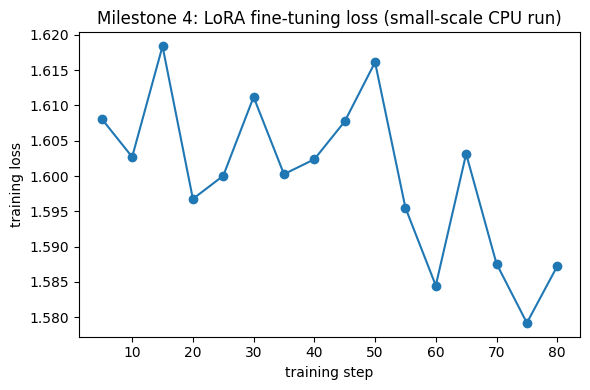

In [7]:
log_history = [l for l in trainer.state.log_history if 'loss' in l]
steps = [l['step'] for l in log_history]
losses = [l['loss'] for l in log_history]

plt.figure(figsize=(6, 4))
plt.plot(steps, losses, marker='o')
plt.xlabel('training step')
plt.ylabel('training loss')
plt.title('Milestone 4: LoRA fine-tuning loss (small-scale CPU run)')
plt.tight_layout()
plt.savefig('../reports/milestone4_training_loss.png', dpi=120)
plt.show()

In [8]:
after_map3 = predict_rankings(model, val_tok, val_df)
print(f'mAP@3 BEFORE fine-tuning: {before_map3:.4f}')
print(f'mAP@3 AFTER fine-tuning:  {after_map3:.4f}')

adapter_dir = '../models/milestone4_lora_adapter'
model.save_pretrained(adapter_dir)
import os
adapter_size_mb = sum(os.path.getsize(os.path.join(adapter_dir, f)) for f in os.listdir(adapter_dir)) / 1e6
print(f'saved LoRA adapter ({adapter_size_mb:.1f} MB) to {adapter_dir}')

mAP@3 BEFORE fine-tuning: 0.3375
mAP@3 AFTER fine-tuning:  0.5208


saved LoRA adapter (3.0 MB) to ../models/milestone4_lora_adapter


## 6. Comparison with earlier milestones, and scaling to GPU

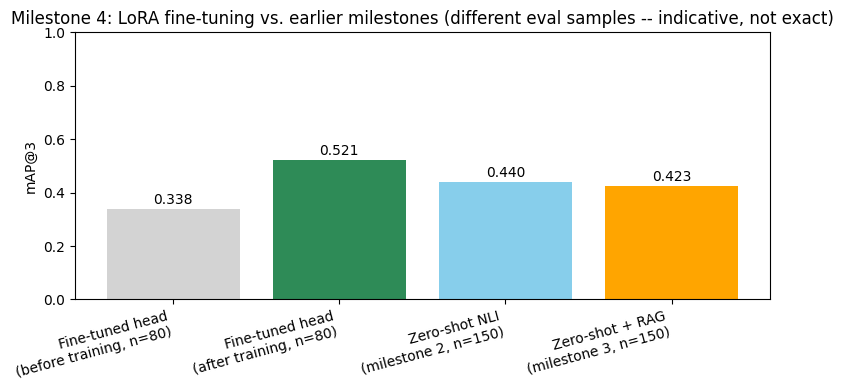

In [9]:
results = pd.DataFrame([
    {'method': 'Fine-tuned head\n(before training, n=80)', 'map3': before_map3},
    {'method': 'Fine-tuned head\n(after training, n=80)', 'map3': after_map3},
    {'method': 'Zero-shot NLI\n(milestone 2, n=150)', 'map3': 0.4400},
    {'method': 'Zero-shot + RAG\n(milestone 3, n=150)', 'map3': 0.4233},
])
plt.figure(figsize=(8, 4))
bars = plt.bar(results['method'], results['map3'], color=['lightgray', 'seagreen', 'skyblue', 'orange'])
plt.ylabel('mAP@3')
plt.title('Milestone 4: LoRA fine-tuning vs. earlier milestones (different eval samples -- indicative, not exact)')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1)
for bar, v in zip(bars, results['map3']):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.savefig('../reports/milestone4_map3_comparison.png', dpi=120)
plt.show()

## 7. Takeaways

- This is a **320-example, 2-epoch, `max_length=48` CPU proof-of-concept**
  -- explicitly not competitive with a real GPU run, and the numbers above
  should be read as "does the pipeline work and move in the right
  direction," not as a leaderboard result.
- To scale to a GPU run (Kaggle/Colab, per the course's own recommended
  workflow), change only constants, not code: `SAMPLE_N` -> full 2000-row
  train set (or all of it plus more epochs), `MAX_LENGTH` -> 96-128 (per
  milestone 1's token-length EDA), `per_device_train_batch_size` -> as
  large as memory allows, `fp16=True` (already conditional on
  `GPU_AVAILABLE`), and consider a larger LoRA rank (`r=16` or `32`) with
  more data available to fit.
- Unlike zero-shot NLI (milestone 2) or RAG-augmented zero-shot
  (milestone 3), fine-tuning directly optimizes the model's weights
  *for this exact task and label distribution* rather than leaning on
  generic pretrained/NLI knowledge -- at full scale this is the approach
  most likely to beat both, precisely because it isn't limited by what a
  frozen general-purpose model already happened to know.
- The LoRA adapter saved above is a few MB, independent of how much
  larger `SAMPLE_N` gets on a full GPU run -- checkpoint size scales with
  trainable-parameter count, not dataset size.